<a href="https://colab.research.google.com/github/karthik-2627/Heart-Disease-Prediction/blob/main/Heart_Diesease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Title : Heart Disease Prediction using Machine Learning

# Objective :
To develop a reliable Machine Learning-based heart disease prediction system that helps healthcare professionals identify potentially high-risk patients early and make informed decisions regarding preventive care.

# Problem type :
Supervised Machine Learning – Binary Classification
- Domain: Healthcare
- Problem Category: Classification
- Learning Type: Supervised Learning
- Target Variable: Heart Disease (Presence or Absence)
- Input: Patient health-related features such as age, blood pressure, cholesterol, chest pain, and heart rate.
- Output: Prediction of whether a patient has a potential risk of heart disease.

# Problem Statement
Develop a Machine Learning model to predict potential heart disease and provide recommendations to hospitals for early detection and prevention.

# Import Libraries
Importing required libraries

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Machine Learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Load Datasets

In [ ]:
values = pd.read_csv("/content/values.csv")
labels = pd.read_csv("/content/labels.csv")
#merge datasets
df = values.merge(labels,on = "patient_id")

In [ ]:
df.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


# Data Understanding :
Basic Steps:

In [ ]:
df.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [ ]:
df.tail()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
175,5qfar3,2,reversible_defect,125,4,2,1,0,254,0.2,1,67,163,0,1
176,2s2b1f,2,normal,180,4,0,0,1,327,3.4,0,55,117,1,1
177,nsd00i,2,reversible_defect,125,3,0,0,0,309,1.8,1,64,131,1,1
178,0xw93k,1,normal,124,3,2,1,0,255,0.0,1,48,175,0,0
179,2nx10r,1,normal,160,3,1,0,0,201,0.0,0,54,163,0,0


In [ ]:
df.columns

Index(['patient_id', 'slope_of_peak_exercise_st_segment', 'thal',
       'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [ ]:
df.dtypes

,0
patient_id,object
slope_of_peak_exercise_st_segment,int64
thal,object
resting_blood_pressure,int64
chest_pain_type,int64
num_major_vessels,int64
fasting_blood_sugar_gt_120_mg_per_dl,int64
resting_ekg_results,int64
serum_cholesterol_mg_per_dl,int64
oldpeak_eq_st_depression,float64


In [ ]:
df.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667,0.444444
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474,0.498290
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000,1.000000


In [ ]:
df.isnull().sum()

,0
patient_id,0
slope_of_peak_exercise_st_segment,0
thal,0
resting_blood_pressure,0
chest_pain_type,0
num_major_vessels,0
fasting_blood_sugar_gt_120_mg_per_dl,0
resting_ekg_results,0
serum_cholesterol_mg_per_dl,0
oldpeak_eq_st_depression,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop("patient_id",axis = 1,inplace = True)

In [ ]:
df.columns

Index(['slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure',
       'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')

In [ ]:
df["thal"].value_counts()

,count
thal,
normal,98
reversible_defect,74
fixed_defect,8


In [ ]:
df = pd.get_dummies(
    df,
    columns=["thal"],
    drop_first=True,
    dtype=int
)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   slope_of_peak_exercise_st_segment     180 non-null    int64  
 1   resting_blood_pressure                180 non-null    int64  
 2   chest_pain_type                       180 non-null    int64  
 3   num_major_vessels                     180 non-null    int64  
 4   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 5   resting_ekg_results                   180 non-null    int64  
 6   serum_cholesterol_mg_per_dl           180 non-null    int64  
 7   oldpeak_eq_st_depression              180 non-null    float64
 8   sex                                   180 non-null    int64  
 9   age                                   180 non-null    int64  
 10  max_heart_rate_achieved               180 non-null    int64  
 11  exercise_induced_an

# In this data no required to Handling Missing Values step

# **EXPLORATORY DATA ANALYSIS**

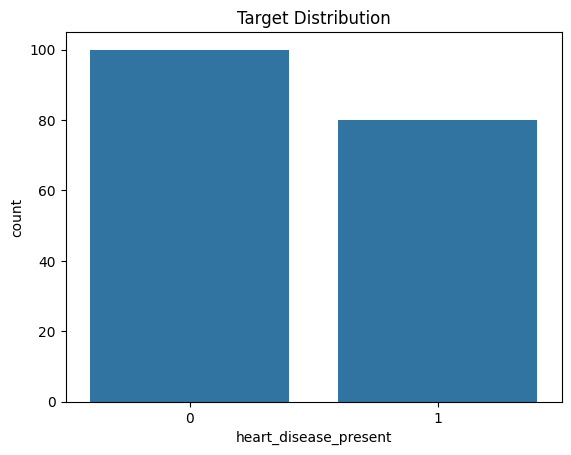

In [ ]:
# Target Distribution
sns.countplot(x = df["heart_disease_present"] ,data = df)
plt.title("Target Distribution")
plt.show()


In [ ]:
df["heart_disease_present"].value_counts()


,count
heart_disease_present,
0,100
1,80


# **Preprocessing**

In [ ]:
col_num = df.select_dtypes(include = ["int","float64"]).columns
col_num

Index(['slope_of_peak_exercise_st_segment', 'resting_blood_pressure',
       'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present', 'thal_normal', 'thal_reversible_defect'],
      dtype='object')

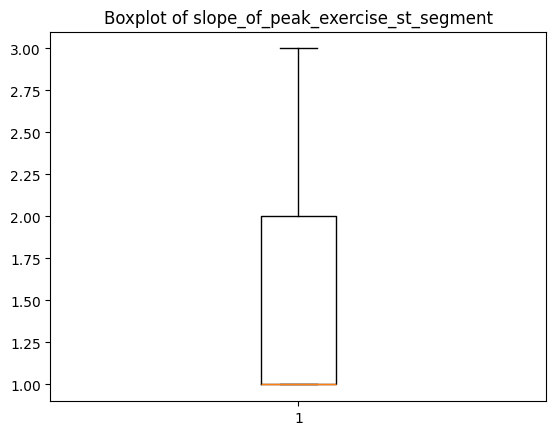

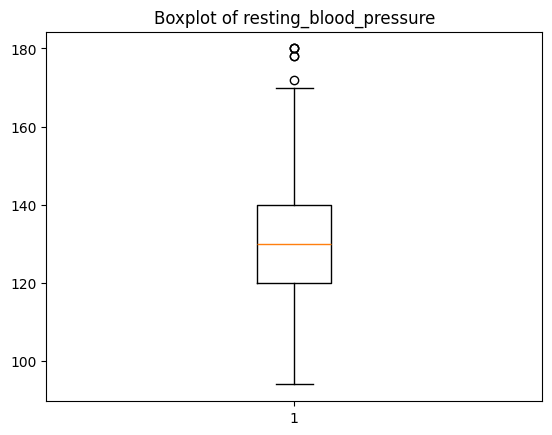

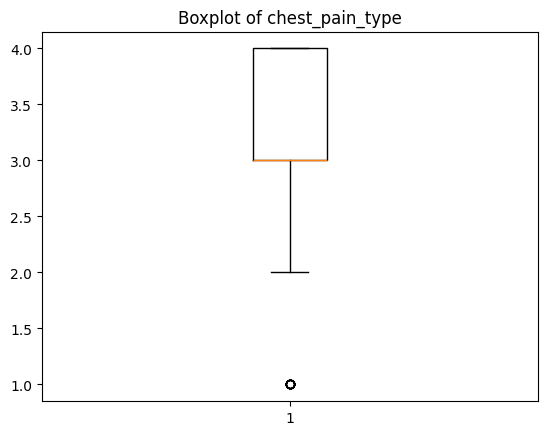

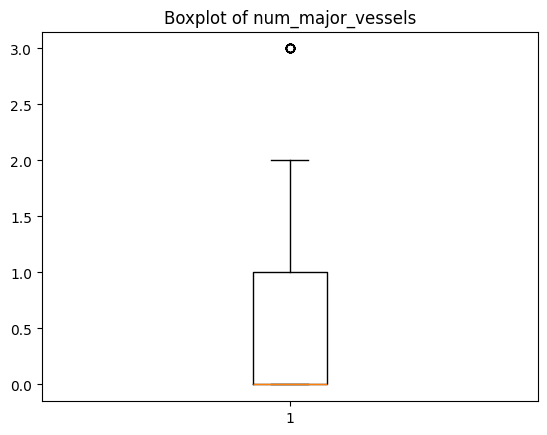

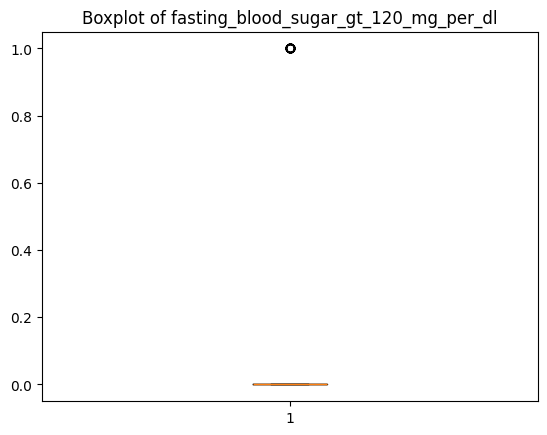

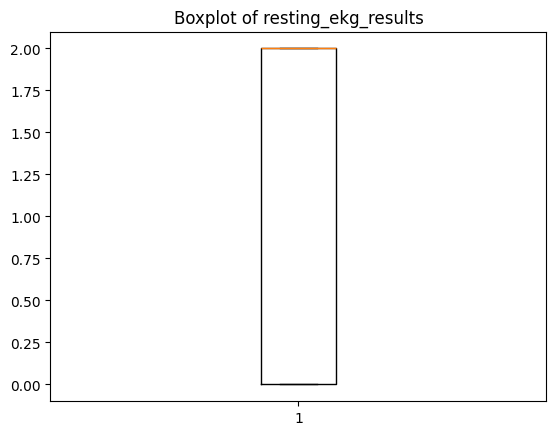

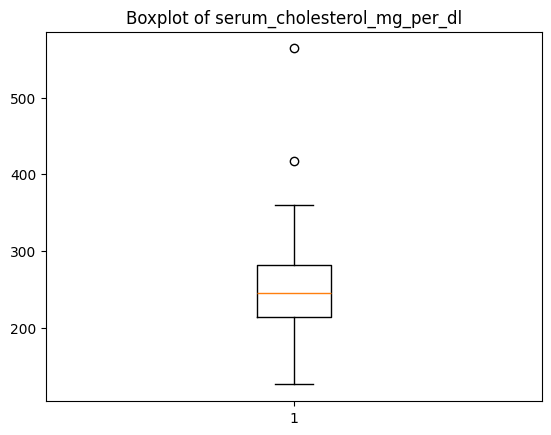

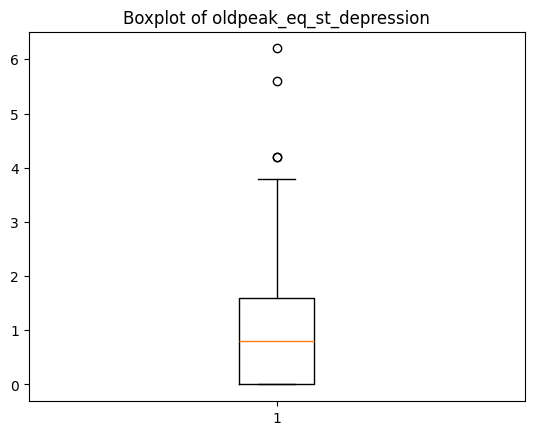

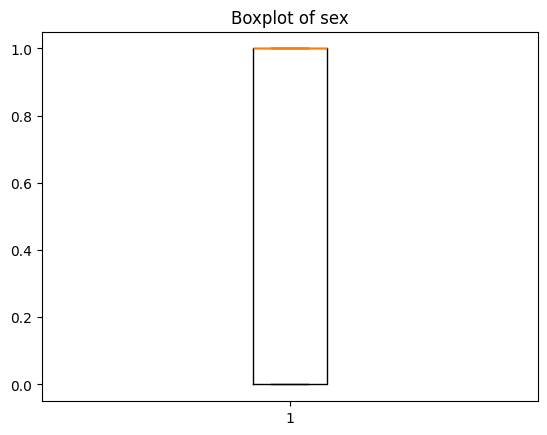

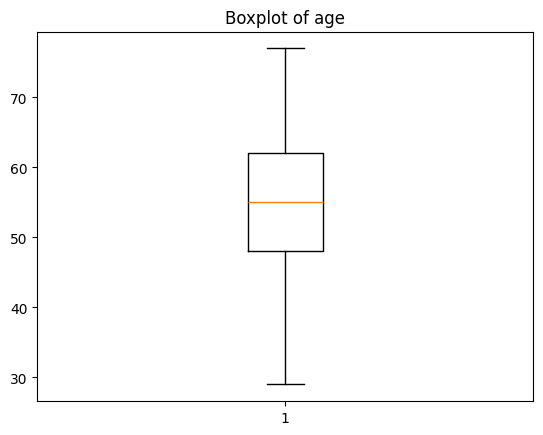

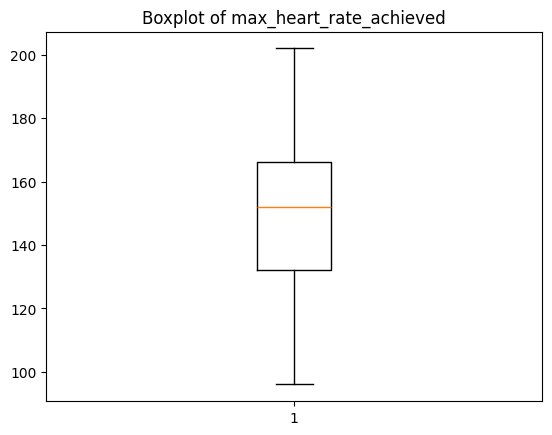

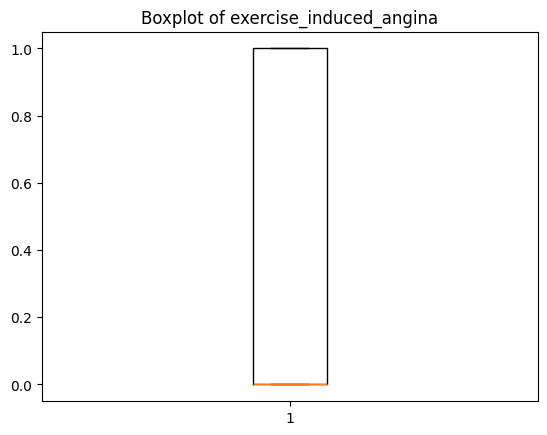

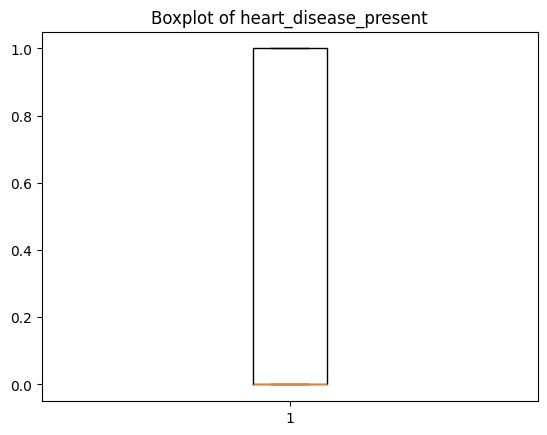

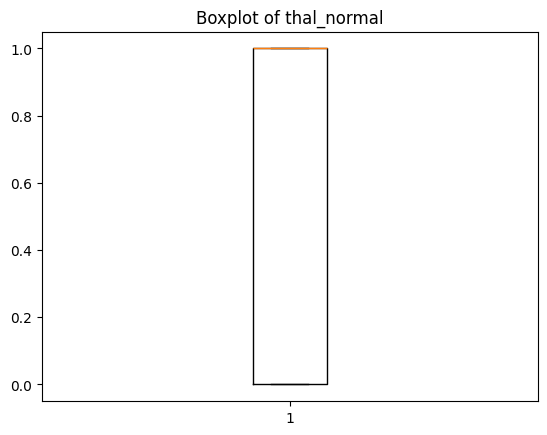

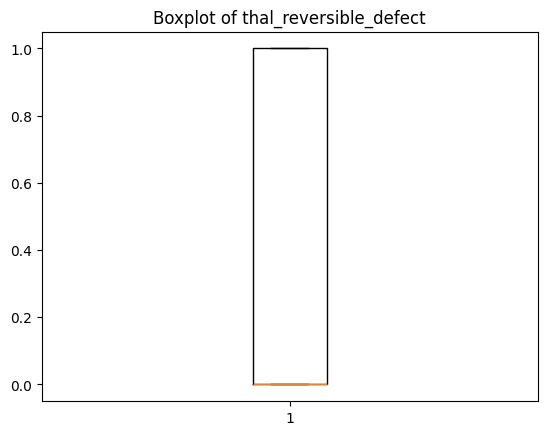

In [ ]:
import matplotlib.pyplot as plt

for col in col_num:
  plt.figure()
  plt.boxplot(df[col])
  plt.title(f"Boxplot of {col}")
  plt.show()

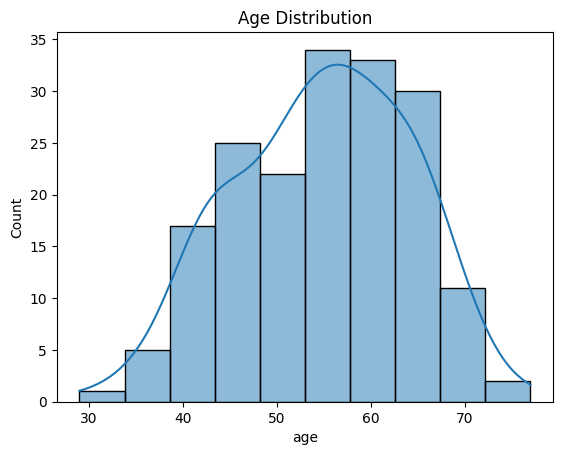

In [ ]:
sns.histplot(
    df["age"],
    kde=True
)

plt.title("Age Distribution")
plt.show()

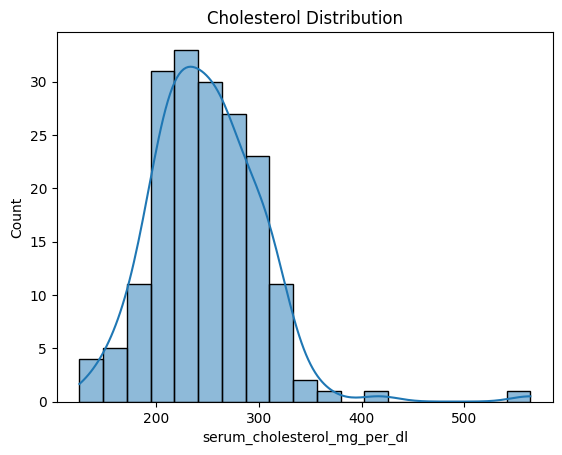

In [ ]:
sns.histplot(
    df["serum_cholesterol_mg_per_dl"],
    kde=True
)

plt.title("Cholesterol Distribution")
plt.show()

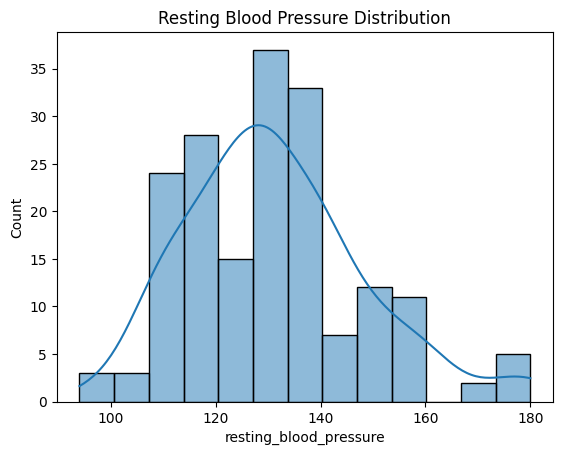

In [ ]:
sns.histplot(
    df["resting_blood_pressure"],
    kde=True
)

plt.title("Resting Blood Pressure Distribution")
plt.show()

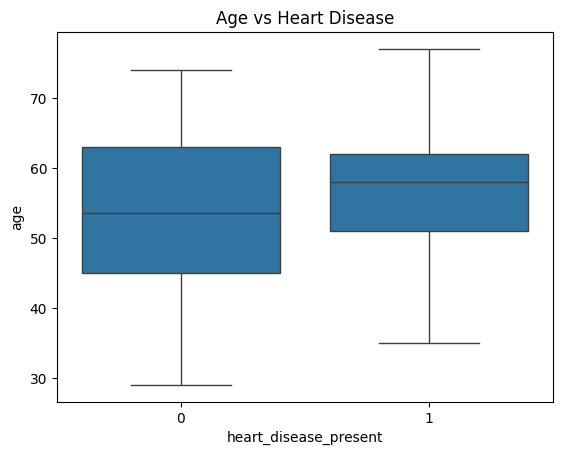

In [ ]:
sns.boxplot(
    data=df,
    x="heart_disease_present",
    y="age"
)

plt.title("Age vs Heart Disease")
plt.show()

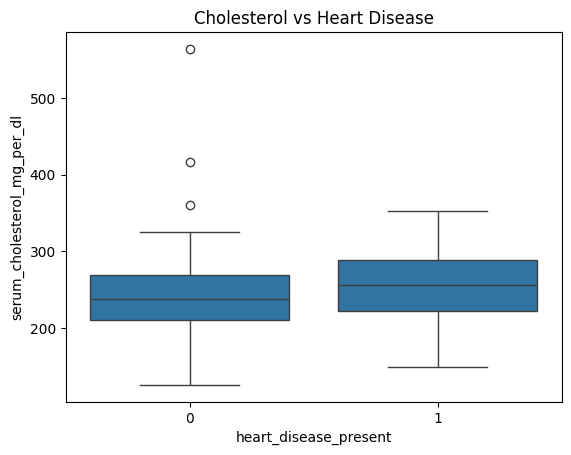

In [ ]:
sns.boxplot(
    data=df,
    x="heart_disease_present",
    y="serum_cholesterol_mg_per_dl"
)

plt.title("Cholesterol vs Heart Disease")
plt.show()

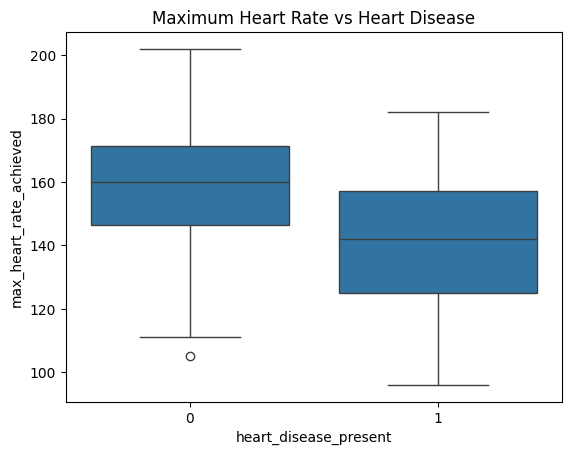

In [ ]:
sns.boxplot(
    data=df,
    x="heart_disease_present",
    y="max_heart_rate_achieved"
)

plt.title("Maximum Heart Rate vs Heart Disease")
plt.show()

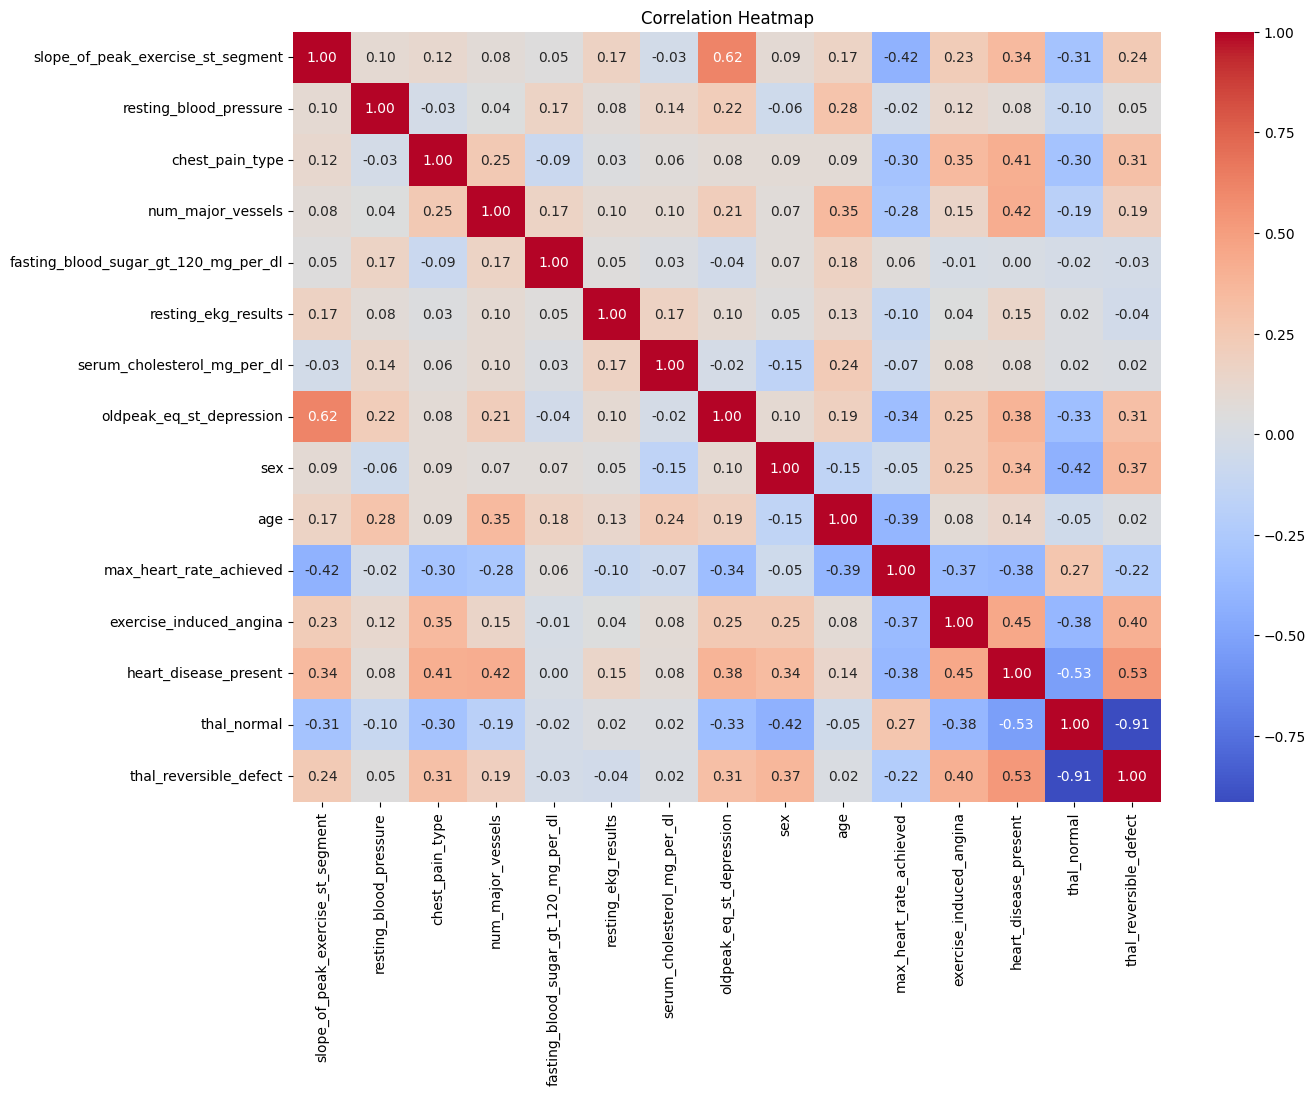

In [ ]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
corr["heart_disease_present"].sort_values(
    ascending=False
)

,heart_disease_present
heart_disease_present,1.000000
thal_reversible_defect,0.525145
exercise_induced_angina,0.448647
num_major_vessels,0.421519
chest_pain_type,0.412829
oldpeak_eq_st_depression,0.382930
slope_of_peak_exercise_st_segment,0.344224
sex,0.335421
resting_ekg_results,0.145933
age,0.138255


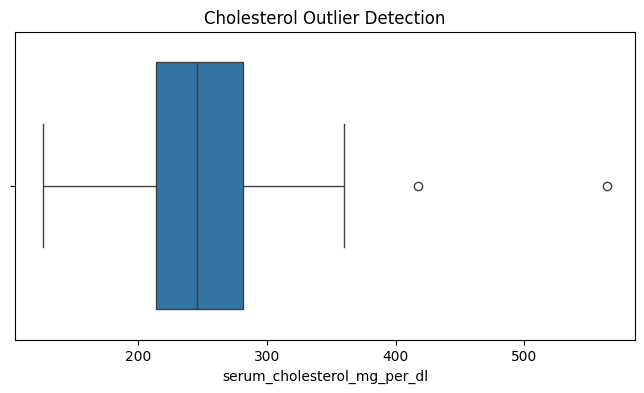

In [ ]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df["serum_cholesterol_mg_per_dl"]
)

plt.title("Cholesterol Outlier Detection")
plt.show()

# Feature Engineering

In [ ]:
df = pd.get_dummies(df, drop_first=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   slope_of_peak_exercise_st_segment     180 non-null    int64  
 1   resting_blood_pressure                180 non-null    int64  
 2   chest_pain_type                       180 non-null    int64  
 3   num_major_vessels                     180 non-null    int64  
 4   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 5   resting_ekg_results                   180 non-null    int64  
 6   serum_cholesterol_mg_per_dl           180 non-null    int64  
 7   oldpeak_eq_st_depression              180 non-null    float64
 8   sex                                   180 non-null    int64  
 9   age                                   180 non-null    int64  
 10  max_heart_rate_achieved               180 non-null    int64  
 11  exercise_induced_an

# Train_Test split

In [ ]:
x = df.drop("heart_disease_present" , axis = 1)
y = df["heart_disease_present"]
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

In [ ]:
x_train.shape

(144, 14)

In [ ]:
x_test.shape

(36, 14)

In [ ]:
y_train.shape

(144,)

In [ ]:
y_test.shape

(36,)

In [ ]:
x.shape

(180, 14)

In [ ]:
y.shape

(180,)

# Feature Scaling

In [ ]:
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


# Logistic_Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train model using already scaled x_train
lr_model.fit(x_train, y_train)

# Predictions using already scaled x_test
y_pred_lr = lr_model.predict(x_test)

# Prediction probabilities
y_prob_lr = lr_model.predict_proba(x_test)[:, 1]

# Evaluation Metrics – Model 1









Objective: Evaluate the performance of Logistic Regression.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("LOGISTIC REGRESSION - MODEL 1")

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("Precision:",
      precision_score(y_test, y_pred_lr, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_lr, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred_lr, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

LOGISTIC REGRESSION - MODEL 1
Accuracy: 0.8333333333333334
Precision: 0.9375
Recall: 0.75
F1 Score: 0.8333333333333334
ROC-AUC: 0.89375

Confusion Matrix:
[[15  1]
 [ 5 15]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.94      0.83        16
           1       0.94      0.75      0.83        20

    accuracy                           0.83        36
   macro avg       0.84      0.84      0.83        36
weighted avg       0.85      0.83      0.83        36



# Random Forest – Model 2

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model using lowercase scaled variables
rf_model.fit(x_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(x_test)

# Prediction probabilities
y_prob_rf = rf_model.predict_proba(x_test)[:, 1]

# Evaluation Metrics – Model 2

In [ ]:
print("RANDOM FOREST - MODEL 2")

print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Precision:",
      precision_score(y_test, y_pred_rf, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_rf, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred_rf, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

RANDOM FOREST - MODEL 2
Accuracy: 0.8611111111111112
Precision: 1.0
Recall: 0.75
F1 Score: 0.8571428571428571
ROC-AUC: 0.8875000000000001

Confusion Matrix:
[[16  0]
 [ 5 15]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      1.00      0.86        16
           1       1.00      0.75      0.86        20

    accuracy                           0.86        36
   macro avg       0.88      0.88      0.86        36
weighted avg       0.89      0.86      0.86        36



# Hyperparameter Tuning – GridSearchCV
Objective: Find the best hyperparameter combination for Random Forest.

Hyperparameters are settings that control how the algorithm learns.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define hyperparameters
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1
)

# Train and tune using the correct lowercase x_train variable
grid_search.fit(x_train, y_train)

# Best parameters
print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV ROC-AUC:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Best CV ROC-AUC:
0.9053571428571429


# Final Model Evaluation – Tuned Random Forest

In [51]:
# Get best model
best_rf_model = grid_search.best_estimator_

# Final predictions
y_pred_final = best_rf_model.predict(x_test)

# Final probabilities
y_prob_final = best_rf_model.predict_proba(x_test)[:, 1]

print("FINAL MODEL EVALUATION")

print("Accuracy:",
      accuracy_score(y_test, y_pred_final))

print("Precision:",
      precision_score(y_test, y_pred_final, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_final, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred_final, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final, zero_division=0))

FINAL MODEL EVALUATION
Accuracy: 0.8611111111111112
Precision: 1.0
Recall: 0.75
F1 Score: 0.8571428571428571
ROC-AUC: 0.890625

Confusion Matrix:
[[16  0]
 [ 5 15]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      1.00      0.86        16
           1       1.00      0.75      0.86        20

    accuracy                           0.86        36
   macro avg       0.88      0.88      0.86        36
weighted avg       0.89      0.86      0.86        36



# ROC-AUC Curve

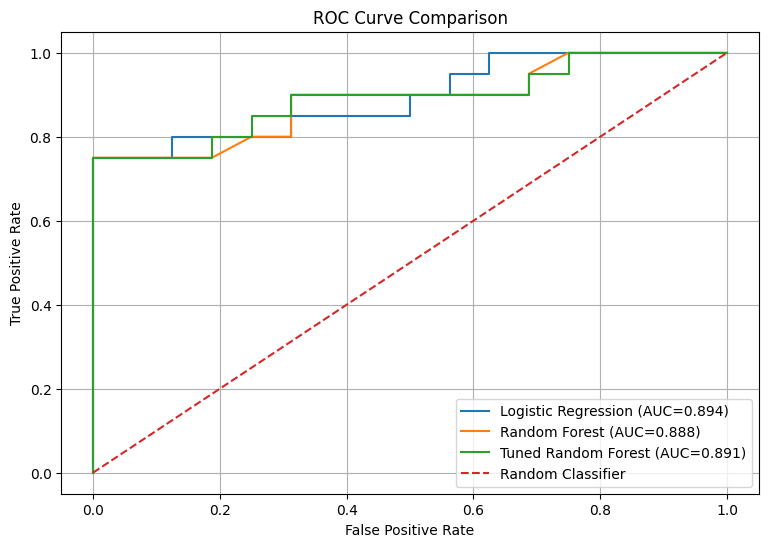

In [52]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

fpr_final, tpr_final, _ = roc_curve(y_test, y_prob_final)

# Calculate AUC scores
auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_rf = roc_auc_score(y_test, y_prob_rf)
auc_final = roc_auc_score(y_test, y_prob_final)

# Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(fpr_lr, tpr_lr,
         label=f'Logistic Regression (AUC={auc_lr:.3f})')

plt.plot(fpr_rf, tpr_rf,
         label=f'Random Forest (AUC={auc_rf:.3f})')

plt.plot(fpr_final, tpr_final,
         label=f'Tuned Random Forest (AUC={auc_final:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--',
         label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

plt.legend()
plt.grid()
plt.show()

# Feature Importance

In [55]:
importance_df = pd.DataFrame({
    'Feature': x.columns,
    'Importance': best_rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

                                 Feature  Importance
7               oldpeak_eq_st_depression    0.111380
10               max_heart_rate_achieved    0.111210
2                        chest_pain_type    0.098437
13                thal_reversible_defect    0.091480
9                                    age    0.090386
3                      num_major_vessels    0.089364
6            serum_cholesterol_mg_per_dl    0.085847
12                           thal_normal    0.075142
11               exercise_induced_angina    0.072751
1                 resting_blood_pressure    0.071862
0      slope_of_peak_exercise_st_segment    0.041298
8                                    sex    0.025308
5                    resting_ekg_results    0.025161
4   fasting_blood_sugar_gt_120_mg_per_dl    0.010374


# Conclusion :

The main objective of this project was to develop a Machine Learning model to predict the possibility of heart disease using patient medical information.

In this project, Exploratory Data Analysis (EDA) and Feature Engineering were performed to understand and prepare the dataset. Two classification algorithms, Logistic Regression and Random Forest, were implemented and evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

GridSearchCV was applied to optimize the Random Forest model by identifying suitable hyperparameters. The models were compared to identify the best-performing model based on evaluation metrics.

This project demonstrates how Machine Learning can support preliminary heart disease risk assessment and potentially assist healthcare professionals in early screening. However, the model requires further validation using larger, independent clinical datasets before any real-world medical application.

# Final result :

- Logistic Regression provides a baseline classification result.
- Random Forest provides a second model for comparison.
- Tuned Random Forest uses the best hyperparameters identified through GridSearchCV.
- The final model should be selected based on its overall test performance, especially recall and ROC-AUC, rather than accuracy alone.



# Challenges Faced

1. Dataset Understanding: Understanding the medical features and their relationship with heart disease.

2. Data Integration: Combining patient values and labels using patient_id.

3. Categorical Encoding: Converting categorical variables into numerical format using One-Hot Encoding.

4. Feature Scaling: Handling different numerical ranges using StandardScaler.

5. Model Selection: Selecting suitable Machine Learning algorithms for heart disease prediction.

6. Model Evaluation: Comparing models using accuracy, precision, recall, F1-score, and ROC-AUC.

7. Hyperparameter Tuning: Finding the best Random Forest parameters using GridSearchCV.

8. Overfitting: Ensuring the model performs well on unseen testing data.

9. Limited Dataset: Working with only 180 patient records, which may limit model generalization.

10. Feature Importance: Identifying the most influential features in the model's predictions.

In [56]:
!git config --global user.name "karthik-2627"
!git config --global user.email "karthiktirunam2627@gmail.com"